# Week 6: Financial Analysis with Pandas, NumPy and Matplotlib

**Student:** Manthan Parmar  
**Organization:** CS Vision  
**Program:** Financial & Operational Analytics Internship Program  
**Week:** 6  
**Topic:** Advanced NumPy, Pandas & Visualization  
**Duration:** 17 October 2026 – 23 October 2026

## 1. Project Objective

This notebook uses the provided cleaned retail financial dataset to summarize revenue, costs and profit. We will compare products, categories, regions and customer segments, then look at monthly results and create five charts. The calculations use every row in the CSV; no records are removed or values filled in. These totals include all order statuses, so they should not automatically be treated as booked sales.

## 2. Import Libraries

Pandas helps us work with tables, NumPy provides safe numeric checks, and Matplotlib creates the charts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

## 3. Load Dataset

The shared CSV is stored in `data/cleaned`. The path checks below allow this notebook to be run from the workspace folder or any of its subfolders.

In [ ]:
workspace_roots = [Path.cwd(), *Path.cwd().parents]
data_path = next(
    (
        root / "data" / "cleaned" / "financial_retail_clean.csv"
        for root in workspace_roots
        if (root / "data" / "cleaned" / "financial_retail_clean.csv").is_file()
    ),
    None,
)

if data_path is None:
    raise FileNotFoundError(
        "Could not find data/cleaned/financial_retail_clean.csv from the current folder or its parents."
    )

df = pd.read_csv(data_path)
print(f"Loaded file: {data_path}")
print(f"Dataset shape: {df.shape[0]} rows and {df.shape[1]} columns")
df.head()

## 4. Data Inspection

First, view a few records, the dataset dimensions, the column names, and each column's data type.

In [3]:
df.head()

,Transaction_ID,Date,Revenue,Cost,Operating_Expense,Gross_Profit,Net_Profit,Product,Category,Customer_ID,Customer_Segment,Region,City,Quantity,Order_Status,Month,Quarter,Year,Profit_Status
0,TXN100447,1/1/2025,"58,470.21","36,725.89","7,621.28","21,744.32","14,123.04",Monitor,Electronics,CUST1087,Consumer,South,Chennai,4,Completed,January,Q1,2025,Profit
1,TXN100678,1/1/2025,"24,860.80","16,154.15","3,382.73","8,706.65","5,323.92",Smartphone,Electronics,CUST1189,Consumer,North,Delhi,1,Completed,January,Q1,2025,Profit
2,TXN100649,1/1/2025,"29,366.04","18,343.70","5,027.60","11,022.34","5,994.74",Smartphone,Electronics,CUST1163,Consumer,South,Chennai,1,Completed,January,Q1,2025,Profit
3,TXN100756,1/1/2025,"8,456.55","4,776.35","1,291.80","3,680.20","2,388.40",Smartwatch,Accessories,CUST1072,Corporate,West,Ahmedabad,1,Cancelled,January,Q1,2025,Profit
4,TXN100849,1/1/2025,"68,559.66","41,428.90","12,170.47","27,130.76","14,960.29",Laptop,Electronics,CUST1161,Consumer,North,Delhi,1,Completed,January,Q1,2025,Profit


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())

Rows: 850
Columns: 19
Column names:
['Transaction_ID', 'Date', 'Revenue', 'Cost', 'Operating_Expense', 'Gross_Profit', 'Net_Profit', 'Product', 'Category', 'Customer_ID', 'Customer_Segment', 'Region', 'City', 'Quantity', 'Order_Status', 'Month', 'Quarter', 'Year', 'Profit_Status']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Transaction_ID     850 non-null    str    
 1   Date               850 non-null    str    
 2   Revenue            850 non-null    float64
 3   Cost               850 non-null    float64
 4   Operating_Expense  850 non-null    float64
 5   Gross_Profit       850 non-null    float64
 6   Net_Profit         850 non-null    float64
 7   Product            850 non-null    str    
 8   Category           850 non-null    str    
 9   Customer_ID        850 non-null    str    
 10  Customer_Segment   850 non-null    str    
 11  Region             850 non-null    str    
 12  City               850 non-null    str    
 13  Quantity           850 non-null    int64  
 14  Order_Status       850 non-null    str    
 15  Month              850 non-null    str    
 16  Quarter            850 non-null    st

## 5. Data Quality Checks

Check missing values in each column and count duplicate rows. These are checks only: we do not delete or fill any rows in this notebook.

In [6]:
missing_values = df.isnull().sum()
print("Missing values by column:")
display(missing_values.to_frame(name="Missing Values"))

duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Missing values by column:


,Missing Values
Transaction_ID,0
Date,0
Revenue,0
Cost,0
Operating_Expense,0
Gross_Profit,0
Net_Profit,0
Product,0
Category,0
Customer_ID,0


Number of duplicate rows: 0


## 6. Basic Financial Calculations

The totals below are sums of the financial columns in the source file. Gross Profit Margin is Gross Profit divided by Revenue; Net Profit Margin is Net Profit divided by Revenue. The average revenue is the average per transaction.

In [7]:
total_revenue = df["Revenue"].sum()
total_cost = df["Cost"].sum()
total_operating_expenses = df["Operating_Expense"].sum()
total_gross_profit = df["Gross_Profit"].sum()
total_net_profit = df["Net_Profit"].sum()
average_revenue = df["Revenue"].mean()

gross_profit_margin = total_gross_profit / total_revenue * 100 if total_revenue != 0 else np.nan
net_profit_margin = total_net_profit / total_revenue * 100 if total_revenue != 0 else np.nan

financial_summary = pd.DataFrame({
    "Measure": [
        "Total Revenue", "Total Cost", "Total Operating Expenses",
        "Total Gross Profit", "Total Net Profit", "Average Revenue per Transaction",
        "Gross Profit Margin (%)", "Net Profit Margin (%)"
    ],
    "Value": [
        total_revenue, total_cost, total_operating_expenses,
        total_gross_profit, total_net_profit, average_revenue,
        gross_profit_margin, net_profit_margin
    ]
})
financial_summary

,Measure,Value
0,Total Revenue,"61,039,689.51"
1,Total Cost,"39,438,335.24"
2,Total Operating Expenses,"7,682,978.67"
3,Total Gross Profit,"21,601,354.27"
4,Total Net Profit,"13,918,375.60"
5,Average Revenue per Transaction,"71,811.40"
6,Gross Profit Margin (%),35.39
7,Net Profit Margin (%),22.80


### Verify the existing financial calculations

For each row, check whether `Revenue - Cost` matches the supplied Gross Profit, and whether `Gross Profit - Operating Expense` matches the supplied Net Profit. A one-cent tolerance allows for small rounding differences. The original values are not changed.

In [8]:
expected_gross_profit = df["Revenue"] - df["Cost"]
expected_net_profit = df["Gross_Profit"] - df["Operating_Expense"]

gross_profit_matches = np.isclose(
    expected_gross_profit, df["Gross_Profit"], atol=0.01
)
net_profit_matches = np.isclose(
    expected_net_profit, df["Net_Profit"], atol=0.01
)

formula_check = pd.DataFrame({
    "Check": ["Revenue - Cost = Gross Profit", "Gross Profit - Operating Expenses = Net Profit"],
    "Rows Matching": [gross_profit_matches.sum(), net_profit_matches.sum()],
    "Total Rows": [len(df), len(df)],
    "All Rows Match": [gross_profit_matches.all(), net_profit_matches.all()]
})
formula_check

,Check,Rows Matching,Total Rows,All Rows Match
0,Revenue - Cost = Gross Profit,850,850,True
1,Gross Profit - Operating Expenses = Net Profit,850,850,True


## 7. Product Performance Analysis

Group the transactions by product and add Revenue and Net Profit. The results are sorted by Revenue so it is easy to compare the larger product totals.

In [9]:
product_performance = df.groupby("Product").agg(
    Revenue=("Revenue", "sum"),
    Net_Profit=("Net_Profit", "sum")
).sort_values("Revenue", ascending=False)

product_performance

,Revenue,Net_Profit
Product,,
Laptop,"28,023,050.88","6,416,577.50"
Smartphone,"13,624,053.70","3,001,913.64"
Tablet,"4,273,728.49","1,017,224.16"
Monitor,"3,947,910.29","897,454.71"
Desk,"3,185,392.74","659,425.27"
Printer,"2,232,128.32","537,671.44"
Office Chair,"1,967,270.08","450,723.42"
Smartwatch,"1,279,243.67","313,150.06"
Headphones,"1,174,588.23","252,871.28"


## 8. Category Performance Analysis

Compare the total Revenue and Net Profit for each product category. Revenue and profit are shown together because a higher revenue total does not automatically mean a higher profit.

In [10]:
category_performance = df.groupby("Category").agg(
    Revenue=("Revenue", "sum"),
    Net_Profit=("Net_Profit", "sum")
).sort_values("Revenue", ascending=False)

category_performance

,Revenue,Net_Profit
Category,,
Electronics,"52,680,285.38","12,065,201.32"
Furniture,"5,152,662.82","1,110,148.69"
Accessories,"3,206,741.31","743,025.59"


## 9. Regional Analysis

Compare Revenue and Net Profit across the regions in the dataset.

In [11]:
regional_performance = df.groupby("Region").agg(
    Revenue=("Revenue", "sum"),
    Net_Profit=("Net_Profit", "sum")
).sort_values("Revenue", ascending=False)

regional_performance

,Revenue,Net_Profit
Region,,
West,"34,309,749.58","7,924,155.68"
South,"13,379,888.38","3,056,702.72"
North,"10,818,323.38","2,370,668.54"
East,"2,531,728.17","566,848.66"


## 10. Customer Segment Analysis

Compare the same financial measures for each customer segment.

In [12]:
segment_performance = df.groupby("Customer_Segment").agg(
    Revenue=("Revenue", "sum"),
    Net_Profit=("Net_Profit", "sum")
).sort_values("Revenue", ascending=False)

segment_performance

,Revenue,Net_Profit
Customer_Segment,,
Consumer,"33,519,101.11","7,583,633.54"
Corporate,"18,048,904.01","4,173,557.63"
Small Business,"9,471,684.39","2,161,184.43"


## 11. Product Ranking

Rank products separately by Revenue and by Net Profit. Looking at both rankings helps avoid treating sales volume as a substitute for profitability.

In [13]:
top_five_revenue = product_performance.sort_values(
    "Revenue", ascending=False
).head(5)

top_five_net_profit = product_performance.sort_values(
    "Net_Profit", ascending=False
).head(5)

print("Top five products by Revenue:")
display(top_five_revenue)
print("Top five products by Net Profit:")
display(top_five_net_profit)

Top five products by Revenue:


,Revenue,Net_Profit
Product,,
Laptop,"28,023,050.88","6,416,577.50"
Smartphone,"13,624,053.70","3,001,913.64"
Tablet,"4,273,728.49","1,017,224.16"
Monitor,"3,947,910.29","897,454.71"
Desk,"3,185,392.74","659,425.27"


Top five products by Net Profit:


,Revenue,Net_Profit
Product,,
Laptop,"28,023,050.88","6,416,577.50"
Smartphone,"13,624,053.70","3,001,913.64"
Tablet,"4,273,728.49","1,017,224.16"
Monitor,"3,947,910.29","897,454.71"
Desk,"3,185,392.74","659,425.27"


In [14]:
highest_revenue_category = category_performance["Revenue"].idxmax()
highest_revenue_region = regional_performance["Revenue"].idxmax()

print("Highest-revenue category:", highest_revenue_category)
print("Highest-revenue region:", highest_revenue_region)

Highest-revenue category: Electronics
Highest-revenue region: West


## 12. Monthly Financial Analysis

Convert the Date column to a datetime type, then total Revenue and Net Profit by month. Rows without a usable date cannot be assigned to a month, so they are excluded from this monthly table only; they remain in the overall financial calculations above. Revenue growth is calculated as `(this month - previous month) / previous month * 100`. The first month and any month after a zero-revenue month have no percentage growth because the previous value is missing or zero.

In [15]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
invalid_date_count = df["Date"].isnull().sum()
print("Rows with an invalid or missing date:", invalid_date_count)

dated_rows = df.dropna(subset=["Date"]).copy()
dated_rows["Month_Start"] = dated_rows["Date"].dt.to_period("M").dt.to_timestamp()

monthly_financials = dated_rows.groupby("Month_Start").agg(
    Revenue=("Revenue", "sum"),
    Net_Profit=("Net_Profit", "sum")
).sort_values("Month_Start").reset_index()

monthly_financials["Previous_Month_Revenue"] = monthly_financials["Revenue"].shift(1)
safe_previous_revenue = monthly_financials["Previous_Month_Revenue"].replace(0, np.nan)
monthly_financials["Revenue_Growth_%"] = (
    (monthly_financials["Revenue"] - monthly_financials["Previous_Month_Revenue"])
    / safe_previous_revenue * 100
)

monthly_financials

Rows with an invalid or missing date: 0


,Month_Start,Revenue,Net_Profit,Previous_Month_Revenue,Revenue_Growth_%
0,2025-01-01,"4,865,781.43","1,069,866.32",NaN,NaN
1,2025-02-01,"5,508,151.11","1,301,465.73","4,865,781.43",13.20
2,2025-03-01,"4,383,197.83","948,882.90","5,508,151.11",-20.42
3,2025-04-01,"4,982,268.37","1,162,206.42","4,383,197.83",13.67
4,2025-05-01,"5,884,249.97","1,291,035.06","4,982,268.37",18.10
5,2025-06-01,"6,296,528.44","1,429,734.27","5,884,249.97",7.01
6,2025-07-01,"5,391,616.52","1,305,130.24","6,296,528.44",-14.37
7,2025-08-01,"5,092,172.61","1,117,097.24","5,391,616.52",-5.55
8,2025-09-01,"4,373,313.75","1,118,001.08","5,092,172.61",-14.12
9,2025-10-01,"5,762,384.55","1,166,436.00","4,373,313.75",31.76


## 13. Five Visualizations

Each chart uses the dataset summaries above. The five PNG files are also saved in the project's `visualizations` folder.

In [ ]:
workspace_root = data_path.resolve().parents[2]
visualizations_folder = workspace_root / "visualizations" / "week6"
visualizations_folder.mkdir(parents=True, exist_ok=True)
print("Charts will be saved to:", visualizations_folder)

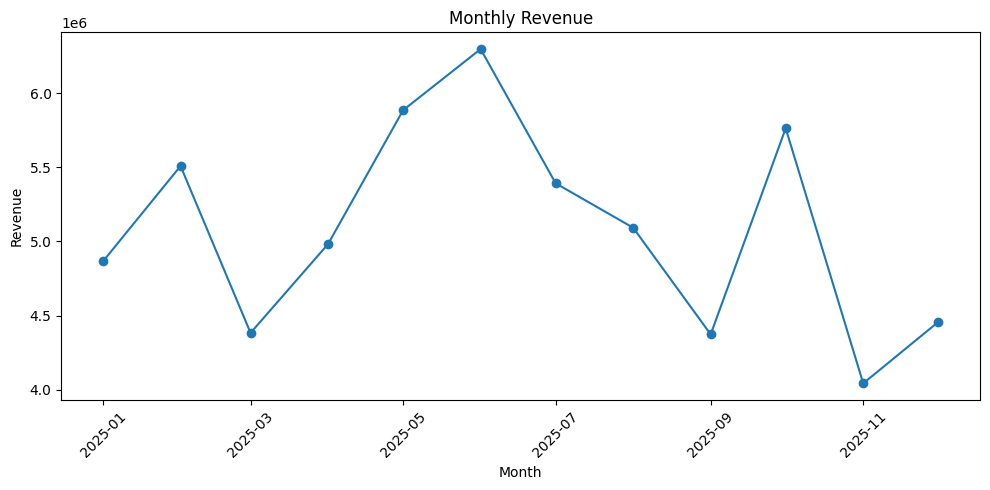

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_financials["Month_Start"], monthly_financials["Revenue"], marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(visualizations_folder / "01_monthly_revenue.png", dpi=150)
plt.show()

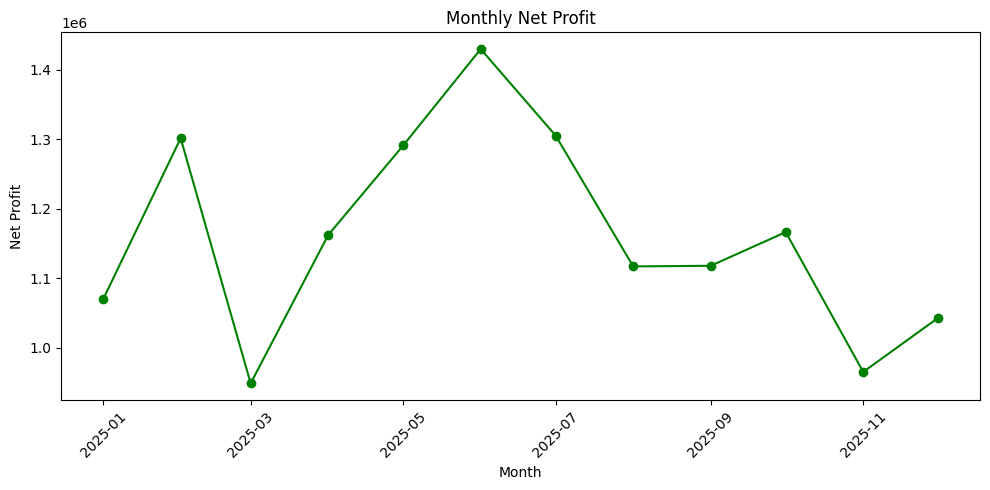

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_financials["Month_Start"], monthly_financials["Net_Profit"], marker="o", color="green")
plt.title("Monthly Net Profit")
plt.xlabel("Month")
plt.ylabel("Net Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(visualizations_folder / "02_monthly_net_profit.png", dpi=150)
plt.show()

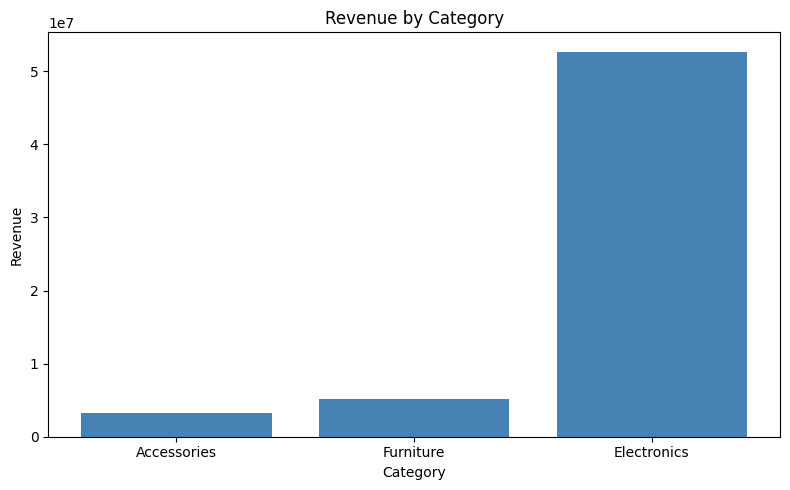

In [19]:
category_chart_data = category_performance.sort_values("Revenue")
plt.figure(figsize=(8, 5))
plt.bar(category_chart_data.index, category_chart_data["Revenue"], color="steelblue")
plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.tight_layout()
plt.savefig(visualizations_folder / "03_category_revenue.png", dpi=150)
plt.show()

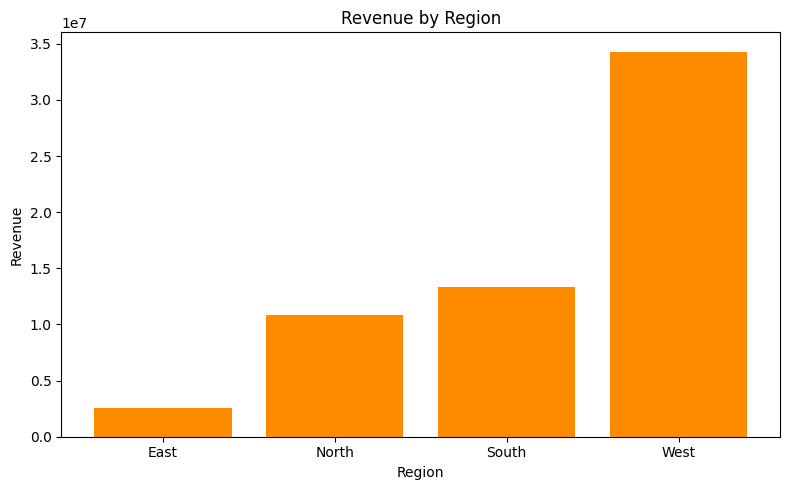

In [20]:
region_chart_data = regional_performance.sort_values("Revenue")
plt.figure(figsize=(8, 5))
plt.bar(region_chart_data.index, region_chart_data["Revenue"], color="darkorange")
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.savefig(visualizations_folder / "04_region_revenue.png", dpi=150)
plt.show()

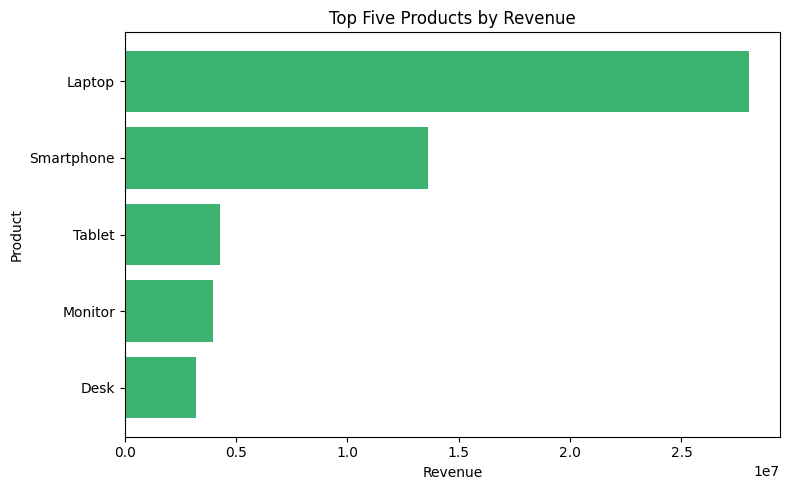

In [21]:
top_products_chart = top_five_revenue.sort_values("Revenue")
plt.figure(figsize=(8, 5))
plt.barh(top_products_chart.index, top_products_chart["Revenue"], color="mediumseagreen")
plt.title("Top Five Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(visualizations_folder / "05_top_five_products_revenue.png", dpi=150)
plt.show()

## 14. Business Insights

These observations come from the grouped results above, using the cleaned CSV:

1. **Laptop** is the leading product by both Revenue (28,023,050.88) and Net Profit (6,416,577.50).
2. **Electronics** is the largest category by Revenue (52,680,285.38) and Net Profit (12,065,201.32).
3. **West** is the leading region by Revenue (34,309,749.58) and Net Profit (7,924,155.68).
4. **Consumer** is the largest customer segment by Revenue (33,519,101.11) and Net Profit (7,583,633.54).
5. For these product, category, region and segment totals, the same group ranks first in both Revenue and Net Profit. The rankings were checked separately; Revenue alone should not be used to infer profitability.

## 15. Conclusion

This analysis used Pandas to inspect the cleaned dataset, calculate financial totals, compare grouped performance and summarize monthly results. NumPy helped check the existing profit calculations within a one-cent tolerance, and Matplotlib showed the five requested comparisons over time and across business groups. In this dataset, Laptop, Electronics, the West region and Consumer customers lead their respective Revenue and Net Profit totals. The results describe the records provided; before treating Revenue as realized sales, review the order statuses and the organization's accounting rules.